TensorFlow version: 2.21.0
Libraries imported successfully!


Saving archive (9).zip to archive (9).zip
Dataset extracted successfully!
Training folder: /content/pest_dataset/pest/train
Testing folder: /content/pest_dataset/pest/test
Found 2700 files belonging to 9 classes.
Found 450 files belonging to 9 classes.

Pest categories: ['aphids', 'armyworm', 'beetle', 'bollworm', 'grasshopper', 'mites', 'mosquito', 'sawfly', 'stem_borer']
Number of classes: 9


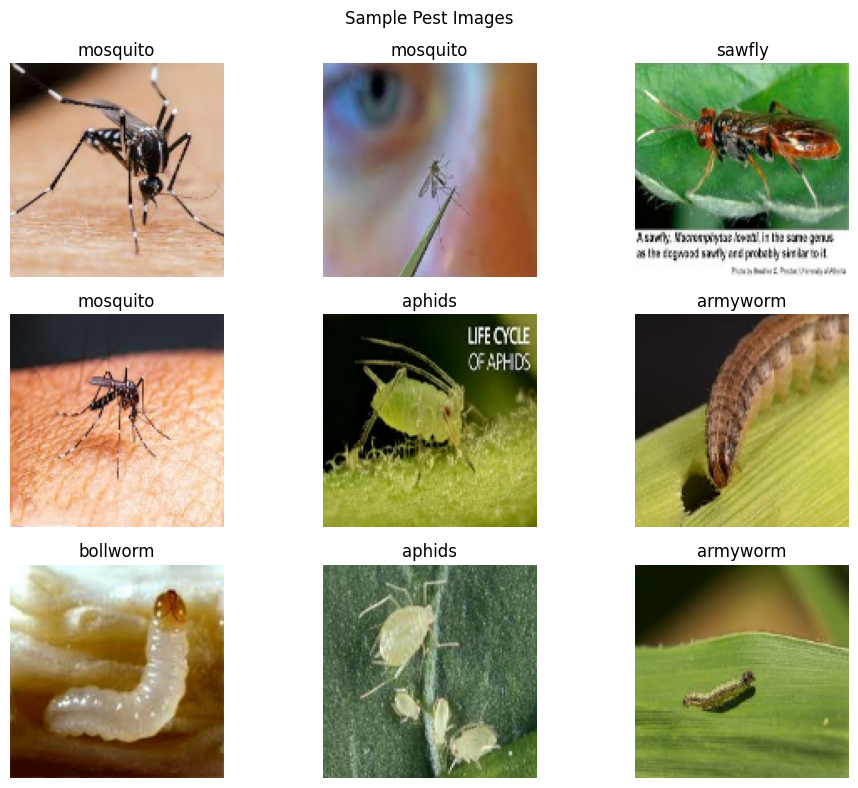

Image normalization completed!

CNN Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,801 (12.61 MB)

 Trainable params: 3,305,801 (12.61 MB)

 Non-trainable params: 0 (0.00 B)


Starting model training...
Epoch 1/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 95s 1s/step - accuracy: 0.2163 - loss: 2.0728 - val_accuracy: 0.3756 - val_loss: 1.7324
Epoch 2/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.5144 - loss: 1.3861 - val_accuracy: 0.7511 - val_loss: 0.8697
Epoch 3/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 94s 1s/step - accuracy: 0.8215 - loss: 0.5397 - val_accuracy: 0.9067 - val_loss: 0.3979
Epoch 4/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 94s 1s/step - accuracy: 0.9556 - loss: 0.1643 - val_accuracy: 0.9400 - val_loss: 0.3565
Epoch 5/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.9685 - loss: 0.1132 - val_accuracy: 0.9489 - val_loss: 0.3643
Epoch 6/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step - accuracy: 0.9837 - loss: 0.0618 - val_accuracy: 0.9378 - val_loss: 0.3608
Epoch 7/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.9863 - loss: 0.0456 - val_accuracy: 0.9400 - val_loss: 0.3397
Epoch 8/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 94s 1s/step - accuracy: 0.9859 - loss: 0.0443 - v

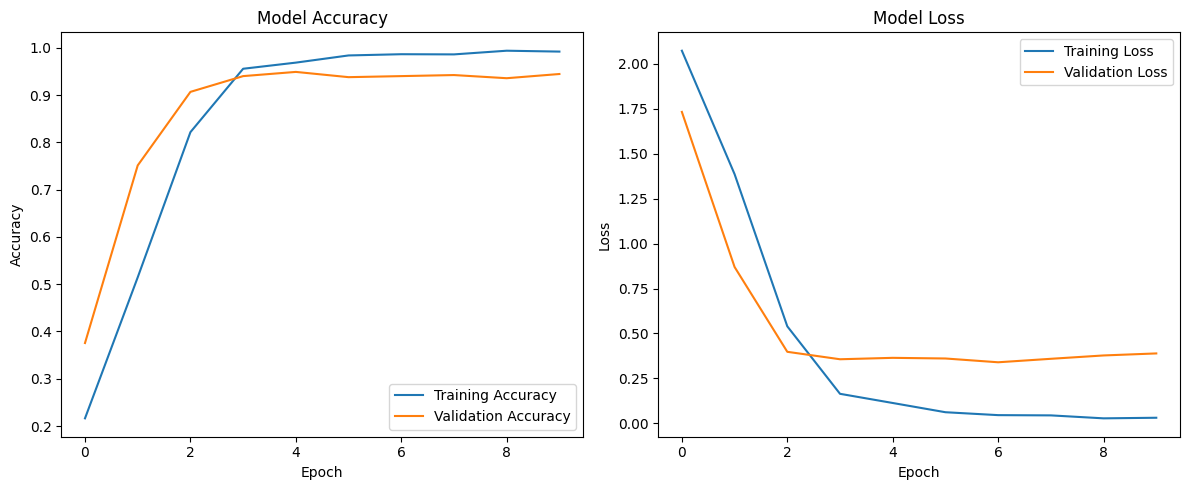

15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 254ms/step - accuracy: 0.9444 - loss: 0.3889

----- MODEL EVALUATION -----
Test Loss: 0.3889
Test Accuracy: 94.44 %


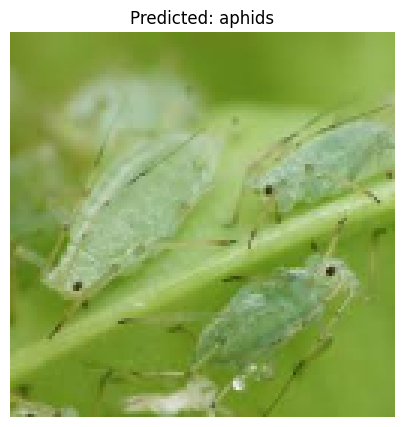

Actual pest: aphids
Predicted pest: aphids
Prediction confidence: 100.0 %

Model saved successfully at: /content/pest_classification_model.keras

PROJECT COMPLETED SUCCESSFULLY!


In [2]:

import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import files
from tensorflow.keras import layers, models

# 1. Import libraries
print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

# 2. Upload and extract dataset
uploaded = files.upload()
zip_path = next(iter(uploaded.keys()))

extract_dir = "/content/pest_dataset"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Dataset extracted successfully!")

# 3. Automatically find training and testing folders
train_dir = None
test_dir = None

for root, dirs, filenames in os.walk(extract_dir):
    if os.path.basename(root).lower() == "train":
        if any(os.path.isdir(os.path.join(root, d)) for d in dirs):
            train_dir = root
    if os.path.basename(root).lower() == "test":
        if any(os.path.isdir(os.path.join(root, d)) for d in dirs):
            test_dir = root

if train_dir is None or test_dir is None:
    raise FileNotFoundError(
        "Training/testing folders were not found. "
        "Check the ZIP folder structure."
    )

print("Training folder:", train_dir)
print("Testing folder:", test_dir)

# 4. Load images
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

if class_names != test_ds.class_names:
    raise ValueError("Training and testing class names do not match!")

print("\nPest categories:", class_names)
print("Number of classes:", num_classes)

# 5. Display sample images
plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
plt.suptitle("Sample Pest Images")
plt.tight_layout()
plt.show()

# 6. Normalize images
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.map(
    lambda x, y: (x / 255.0, y),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds = test_ds.map(
    lambda x, y: (x / 255.0, y),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("Image normalization completed!")

# 7. Build CNN model
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nCNN Model Summary:")
model.summary()

# 8. Train model
print("\nStarting model training...")
history = model.fit(
    train_ds,
    epochs=10,
    validation_data=test_ds
)

# 9. Plot accuracy and loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# 10. Evaluate model
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("\n----- MODEL EVALUATION -----")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# 11. Predict one test image
for images, labels in test_ds.take(1):
    image = images[0]
    actual_label = int(labels[0])

    probabilities = model.predict(
        tf.expand_dims(image, axis=0), verbose=0
    )[0]

    predicted_label = int(np.argmax(probabilities))
    confidence = float(np.max(probabilities) * 100)

    plt.figure(figsize=(5, 5))
    plt.imshow(image.numpy())
    plt.title("Predicted: " + class_names[predicted_label])
    plt.axis("off")
    plt.show()

    print("Actual pest:", class_names[actual_label])
    print("Predicted pest:", class_names[predicted_label])
    print("Prediction confidence:", round(confidence, 2), "%")

# 12. Save trained model
model_path = "/content/pest_classification_model.keras"
model.save(model_path)

print("\nModel saved successfully at:", model_path)
print("\nPROJECT COMPLETED SUCCESSFULLY!")
